In [ ]:
import  tensorflow as tf
import matplotlib.pyplot as plt
import os
import random
import numpy as np

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Rescaling, Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.utils import image_dataset_from_directory


2026-10-10 17:36:31.630419: I tensorflow/core/util/port.cc:113] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-10-10 17:36:31.658197: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-10-10 17:36:32.054949: W tensorflow/compiler/tf2tensorrt/utils/py_utils.cc:38] TF-TRT Warning: Could not find TensorRT
/home/student/.local/lib/python3.10/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3

In [ ]:
DATA_DIR = "/Desktop/BIA39_LPIV_Mock/Pneumonia X Ray/"

In [ ]:
DATA_DIR = os.path.expanduser("~/Desktop/BIA39_LPIV_Mock/Pneumonia X Ray")

print("Dataset exists:", os.path.exists(DATA_DIR))

Dataset exists: True


In [ ]:
if os.path.exists(DATA_DIR):
    print("Contents:", os.listdir(DATA_DIR))

Contents: ['val', 'train', 'chest_xray', '__MACOSX', 'test']


In [ ]:
TRAIN_DIR = os.path.join(DATA_DIR, "train")
TEST_DIR = os.path.join(DATA_DIR, "test")
VAL_DIR = os.path.join(DATA_DIR, "val")

In [ ]:
IMG_SIZE = (150,150)
BATCH_SIZE = 32

In [ ]:
# Load training images
train_ds = image_dataset_from_directory(
    TRAIN_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    seed=123
)

Found 3937 files belonging to 2 classes.


In [ ]:
# Load validation data
val_ds = image_dataset_from_directory(
    VAL_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode ="int"
)

Found 16 files belonging to 2 classes.


In [ ]:
# Load training images
test_ds = image_dataset_from_directory(
    TEST_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

Found 624 files belonging to 2 classes.


In [ ]:
class_names = train_ds.class_names
print("Class names : ", class_names)

Class names :  ['NORMAL', 'PNEUMONIA']


In [ ]:
# Optimize ds loading
AUTOTUNE = tf.data.AUTOTUNE

In [ ]:
train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)

In [ ]:
# Build the model
model = Sequential([
    Input(shape = (150,150,3)),
    Rescaling(1.0/255),

    Conv2D(32,3,activation="relu"),
    MaxPooling2D(),

    Conv2D(64,3,activation="relu"),
    MaxPooling2D(),

    Conv2D(128,3,activation="relu"),
    MaxPooling2D(),

    Flatten(),
    Dense(128, activation="relu"),
    Dropout(0.3),

    Dense(
        len(class_names),
        activation="softmax"
    )
])

In [ ]:
# Compile the model
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [ ]:
# Train the model
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5
)

Epoch 1/5
124/124 ━━━━━━━━━━━━━━━━━━━━ 26s 200ms/step - accuracy: 0.7809 - loss: 0.5258 - val_accuracy: 0.8125 - val_loss: 0.3277
Epoch 2/5
124/124 ━━━━━━━━━━━━━━━━━━━━ 25s 197ms/step - accuracy: 0.9490 - loss: 0.1280 - val_accuracy: 0.8750 - val_loss: 0.3727
Epoch 3/5
124/124 ━━━━━━━━━━━━━━━━━━━━ 26s 205ms/step - accuracy: 0.9631 - loss: 0.1047 - val_accuracy: 0.9375 - val_loss: 0.2365
Epoch 4/5
124/124 ━━━━━━━━━━━━━━━━━━━━ 25s 203ms/step - accuracy: 0.9489 - loss: 0.1378 - val_accuracy: 0.7500 - val_loss: 0.3327
Epoch 5/5
124/124 ━━━━━━━━━━━━━━━━━━━━ 26s 204ms/step - accuracy: 0.9750 - loss: 0.0766 - val_accuracy: 0.9375 - val_loss: 0.2036


In [ ]:
test_loss, test_accuracy = model.evaluate(test_ds, verbose=0)

In [ ]:
print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy * 100, "%")

Test Loss: 0.8154371380805969
Test Accuracy: 81.25 %


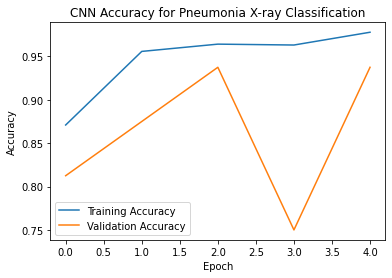

In [ ]:
# Plot training and validation accuracy
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("CNN Accuracy for Pneumonia X-ray Classification")
plt.legend()
plt.show()

In [ ]:
# Select a random batch from the test dataset
test_batches = list(test_ds)
images, labels = random.choice(test_batches)

2026-10-10 18:53:48.055203: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


In [ ]:
# Select a random image from that batch
i = random.randrange(0,len(images))
print(i)

12


In [ ]:
# Get the selected image and actual label
image = images[i]
actual_label = class_names[int(labels[i].numpy())]

In [ ]:
# Predict the selected image
prediction = model.predict(
    tf.expand_dims(image, axis=0),
    verbose=0
)

In [ ]:
predicted_index = np.argmax(prediction[0])
predicted_label = class_names[predicted_index]
confidence = prediction[0][predicted_index] * 100

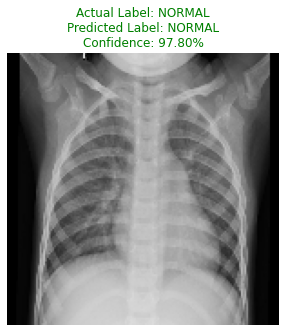

In [ ]:
# Display image and results
plt.figure(figsize=(5, 5))
plt.imshow(image.numpy().astype("uint8"))
plt.axis("off")

color = "green" if actual_label == predicted_label else "red"

plt.title(
    f"Actual Label: {actual_label}\n"
    f"Predicted Label: {predicted_label}\n"
    f"Confidence: {confidence:.2f}%",
    color=color
)

plt.show()